# Link Score Components

We look at raw components (land use diversity and POI diversity) before choosing normalization bounds, aggregation, and weights for the link score. We check how they're distributed, how many links have no POIs, how the components relate to each other, and how they depend on link length.

The goal is to settle open choices for the score:
- whether POI needs a floor
- richness bounds
- whether attractiveness adds information beyond land use diversity
- weights

<br><br>

## 0. Setup

### 0.1. Imports and Config

In [1]:
import numpy as np
import pandas as pd

from splendor.config import (
    CORRIDOR_RADIUS,
    ROAD_STRIP_RADIUS,
    STUDY_AREA,
    DIVERSITY_MEASURES,
    EXCLUDED_TYPES,
    RICHNESS_MIN_SHARE,
)
from splendor.io import load_network
from splendor.landuse.types import N_TYPES
from splendor.paths import network_path, link_diversity_path
from splendor.plotting.charts import plot_counts, plot_distributions, plot_against, plot_scatter_matrix

K = N_TYPES - len(EXCLUDED_TYPES) # Land use types the measures see
THEORETICAL_MAX = { # Reference lines only
    "shannon": np.log(K),
    "inverse_simpson": K,
    "richness": min(K, int(1 / RICHNESS_MIN_SHARE)), # At most 1 / threshold types can reach the threshold
}
TITLES = (
    {m: m.replace("_", " ").capitalize() for m in DIVERSITY_MEASURES} | 
    {"poi": "POI", "attractiveness": "Landscape attractiveness"}
)

### 0.2. Data

In [7]:
_, edges = load_network(network_path(STUDY_AREA))
diversity = pd.read_csv(link_diversity_path(STUDY_AREA, CORRIDOR_RADIUS, ROAD_STRIP_RADIUS))

links = edges[["edge_id", "length_m", "poi_diversity"]].merge(
    diversity, on="edge_id", how="inner", validate="one_to_one"
)
assert len(links) == len(edges) == len(diversity), "edge ids of network and diversity file don't match"

measure_columns = [f"diversity_{m}" for m in DIVERSITY_MEASURES]
component_columns = [*measure_columns, "poi_diversity", "attractiveness"]

print(links[["length_m", *component_columns]].describe().round(3))

        length_m  diversity_shannon  diversity_richness  poi_diversity  \
count    638.000            638.000             638.000        638.000   
mean    2274.977              0.857               2.011          0.978   
std     1711.131              0.337               0.773          0.970   
min        7.826              0.081               1.000          0.000   
25%     1149.609              0.612               2.000          0.000   
50%     2024.219              0.804               2.000          1.000   
75%     3041.310              1.080               2.000          2.000   
max    19793.209              1.931               5.000          3.000   

       attractiveness  
count         638.000  
mean            0.229  
std             0.110  
min             0.000  
25%             0.189  
50%             0.224  
75%             0.250  
max             0.833  


<br><br>

## 1. POI Diversity

               links  share
poi_diversity              
0                247  0.387
1                218  0.342
2                113  0.177
3                 60  0.094


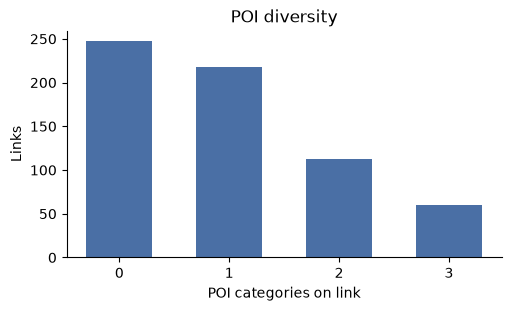

In [3]:
poi_counts = links["poi_diversity"].value_counts().reindex(range(4), fill_value=0)
print(pd.DataFrame({"links": poi_counts, "share": (poi_counts / len(links)).round(3)}))

plot_counts(links, "poi_diversity", range(4), "POI diversity", "POI categories on link");

<br><br>

## 2. Land Use Diversity

            min    max  theoretical_max
shannon   0.081  1.931            2.565
richness  1.000  5.000           10.000


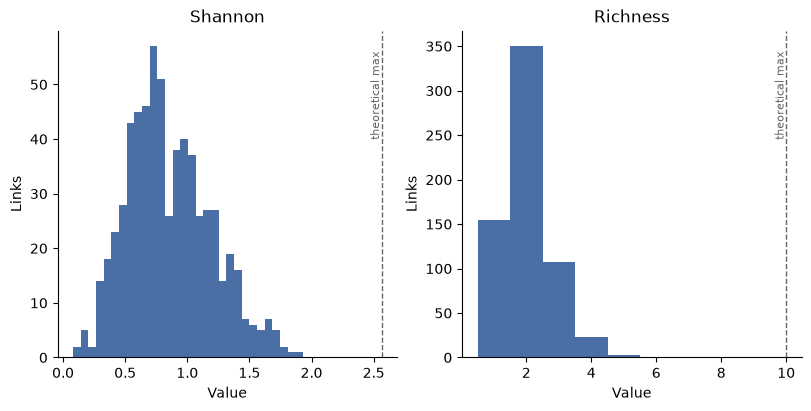

In [8]:
plot_distributions(
    links,
    measure_columns,
    titles=[TITLES[m] for m in DIVERSITY_MEASURES],
    references=[THEORETICAL_MAX[m] for m in DIVERSITY_MEASURES],
    reference_label="theoretical max",
    integer_columns=["diversity_richness"],
);

print(pd.DataFrame({
    "min": [links[f"diversity_{m}"].min() for m in DIVERSITY_MEASURES],
    "max": [links[f"diversity_{m}"].max() for m in DIVERSITY_MEASURES],
    "theoretical_max": [THEORETICAL_MAX[m] for m in DIVERSITY_MEASURES],
}, index=DIVERSITY_MEASURES).round(3))

<br><br>

## 3. Landscape Attractiveness

count    638.000
mean       0.229
std        0.110
min        0.000
25%        0.189
50%        0.224
75%        0.250
max        0.833
Name: attractiveness, dtype: float64


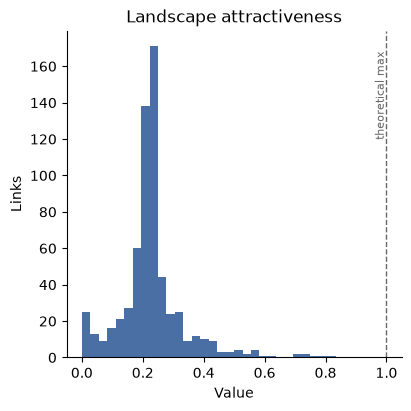

In [10]:
plot_distributions(
    links,
    ["attractiveness"],
    titles=[TITLES["attractiveness"]],
    references=[1.0],
    reference_label="theoretical max",
);
print(links["attractiveness"].describe().round(3))

<br><br>

## 4. Component Relations

                    diversity_shannon  diversity_richness  poi_diversity  \
diversity_shannon                1.00                0.74           0.33   
diversity_richness               0.74                1.00           0.30   
poi_diversity                    0.33                0.30           1.00   
attractiveness                   0.09               -0.14          -0.15   

                    attractiveness  
diversity_shannon             0.09  
diversity_richness           -0.14  
poi_diversity                -0.15  
attractiveness                1.00  


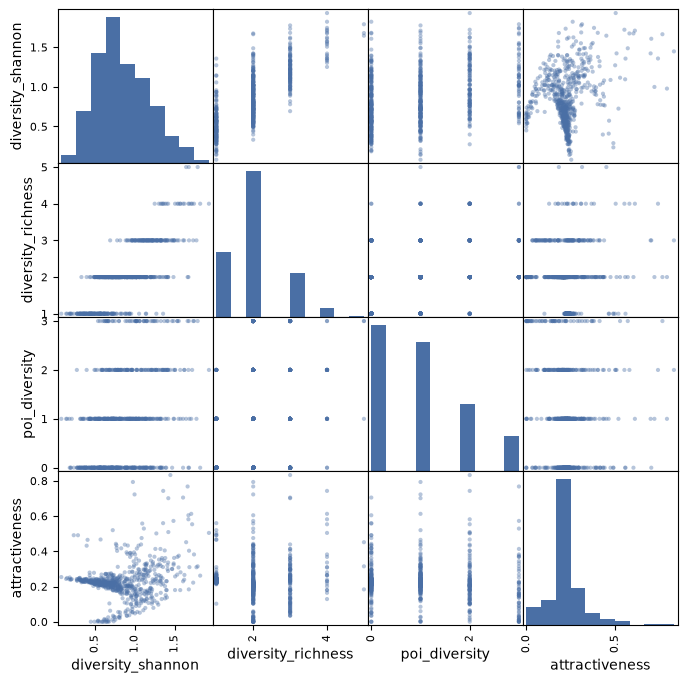

In [5]:
print(links[component_columns].corr(method="spearman").round(2))

plot_scatter_matrix(links, component_columns);

<br><br>

## 5. Length Dependence

diversity_shannon     0.13
diversity_richness   -0.05
poi_diversity         0.15
attractiveness        0.29
Name: length_m, dtype: float64


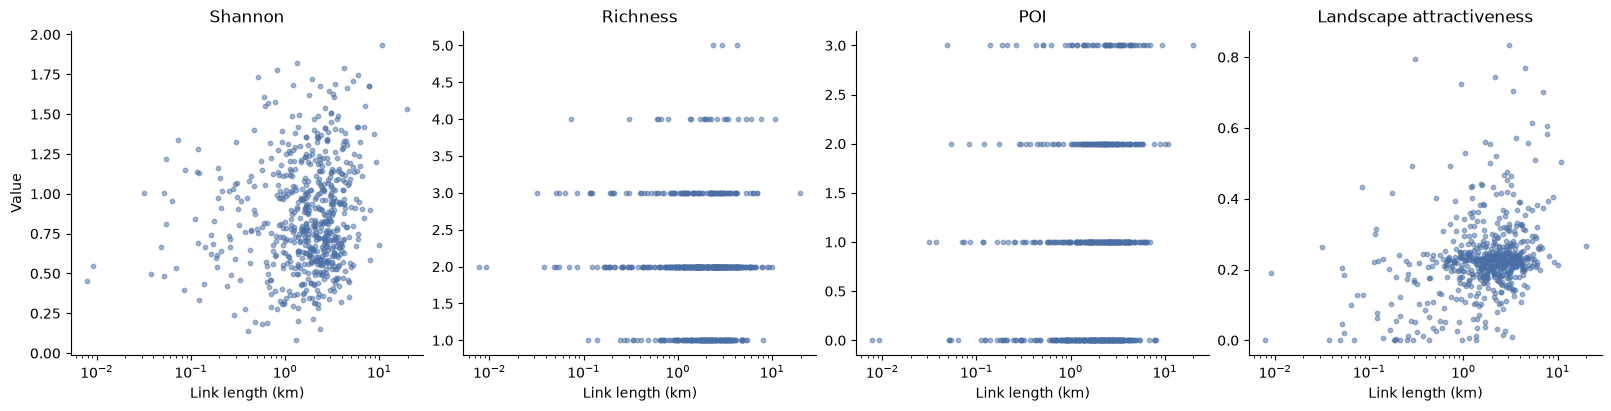

In [6]:
print(links[["length_m", *component_columns]].corr(method="spearman")["length_m"].drop("length_m").round(2))

plot_against(
    links,
    "length_m",
    component_columns,
    titles=[TITLES[m] for m in DIVERSITY_MEASURES] + [TITLES["poi"], TITLES["attractiveness"]],
    xlabel="Link length (km)",
    x_scale_factor=1 / 1000,
    xscale="log",
);

<br><br>

## 6. Conclusion

**POI**

39% of links have no POI categories (34% one, 18% two, 9% three). These links would all score 0 under a geometric mean without a floor, so whether POI gets a floor (bounds (-1, 3)) matters for a large part of the network.

**Land use range**

The data uses only part of the theoretical range (maximum 1.93 of 2.56 for Shannon, 5 of 10 for richness). Normalization by theoretical bounds therefore compresses the scores into the lower part of [0, 1], while percentile and rank normalization spread them out.

**Attractiveness**

Attractiveness is concentrated around the cropland and grassland tier: half of the links lie between 0.19 and 0.25, and the maximum is 0.83. Like land use diversity, it is compressed under bounds normalization and spread out under percentile and rank normalization.

**Relations**

Richness is a coarser version of Shannon (Spearman 0.74). An earlier run showed inverse Simpson ranking links almost identically to Shannon (0.97), so it was dropped. POI is only weakly related to land use (0.30–0.33), and attractiveness is nearly unrelated to the other components (-0.15 to 0.09). Each component carries different information, so the aggregation choice and the weights will matter.

**Length**

Diversity and POI depend only weakly on link length (Spearman between -0.05 and 0.15). Attractiveness depends on it more (0.29), so longer links tend to be more attractive. A few links are very short (down to about 8 m), so their corridors contain few pixels.